# ViDDAR — Cross-dataset comparison **v2** (improved)

Improvements over `viddar_cross_dataset_comparison.ipynb` (v1):

1. **Balanced sampling** — cap per class (v1 was ~65% vehicles).
2. **Better DINO queries** — use the real COCO category (`car`, `motorcycle`, …), synonym prompts, lower thresholds, keep the highest-scoring box.
3. **Domain adaptation** — fine-tune Option B’s mask decoder on the synthetic train split (ViDDAR→COCO transfer alone was not enough).
4. **Fairer evaluation** — report DINO recall; compare zero-shot / ViDDAR-only B / adapted B / oracle on the same images.
5. **Fixed ViDDAR side-by-side** — hardcoded Entrega-2 numbers (CSV name mismatch in v1 left ViDDAR as NaN).

**Runtime (T4):** [0] ~2 min · [1] ~5–10 min (COCO cached if v1 already ran) · [2] DINO+embeddings ~10 min · [3] fine-tune B ~15–25 min · [4]–[6] ~10 min.

**Before running:** Runtime → GPU.


## [0] Setup

In [2]:
import os, sys, json, random, shutil, zipfile, subprocess, copy
from collections import defaultdict

import numpy as np
import pandas as pd
import cv2
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

print("CUDA:", torch.cuda.is_available(), "| GPU:",
      torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE")

from google.colab import drive
drive.mount('/content/drive')

PROJECT_DIR = '/content/drive/MyDrive/viddar_samed'
COMPARE_DIR = f'{PROJECT_DIR}/cross_dataset_v2'
SYNTH_DIR = f'{COMPARE_DIR}/synthetic_coco_balanced'
os.makedirs(COMPARE_DIR, exist_ok=True)
os.makedirs(SYNTH_DIR, exist_ok=True)

shutil.rmtree(f'{PROJECT_DIR}/hf_cache', ignore_errors=True)
os.environ['HF_HOME'] = '/content/hf_cache'
os.makedirs(os.environ['HF_HOME'], exist_ok=True)

if not os.path.exists('/content/segment-anything'):
    subprocess.run(['git', 'clone', '-q',
                    'https://github.com/facebookresearch/segment-anything.git'], cwd='/content')
if not os.path.exists('/content/SAMed'):
    subprocess.run(['git', 'clone', '-q', 'https://github.com/hitachinsk/SAMed.git'], cwd='/content')
    subprocess.run(['pip', 'install', '-q', 'icecream', 'SimpleITK', 'medpy',
                    'tensorboardX', 'ml-collections'])

SAM_CKPT = f'{PROJECT_DIR}/checkpoints/sam_vit_b_01ec64.pth'
os.makedirs(f'{PROJECT_DIR}/checkpoints', exist_ok=True)
if not os.path.exists(SAM_CKPT):
    print("Downloading SAM ViT-B...")
    subprocess.run(['wget', '-q',
                    'https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth',
                    '-O', SAM_CKPT])
os.makedirs('/content/SAMed/checkpoints', exist_ok=True)
shutil.copy(SAM_CKPT, '/content/SAMed/checkpoints/sam_vit_b_01ec64.pth')

sys.path.insert(0, '/content/SAMed')
sys.path.insert(0, '/content/segment-anything')

from transformers import AutoProcessor, AutoModelForZeroShotObjectDetection
dino_processor = AutoProcessor.from_pretrained("IDEA-Research/grounding-dino-tiny")
dino_model = AutoModelForZeroShotObjectDetection.from_pretrained(
    "IDEA-Research/grounding-dino-tiny").to("cuda").eval()
print("Grounding DINO loaded.")

for mod_name in list(sys.modules.keys()):
    if mod_name == 'segment_anything' or mod_name.startswith('segment_anything.'):
        del sys.modules[mod_name]
sys.path.insert(0, '/content/segment-anything')
from segment_anything import sam_model_registry as sam_model_registry_orig
from segment_anything.utils.transforms import ResizeLongestSide

sam_baseline = sam_model_registry_orig['vit_b'](
    checkpoint='/content/SAMed/checkpoints/sam_vit_b_01ec64.pth')
sam_baseline.cuda().eval()
print("SAM original loaded.")


def reload_original_sam():
    for mod_name in list(sys.modules.keys()):
        if mod_name == 'segment_anything' or mod_name.startswith('segment_anything.'):
            del sys.modules[mod_name]
    sys.path.insert(0, '/content/segment-anything')
    from segment_anything import sam_model_registry as _reg
    sam = _reg['vit_b'](checkpoint='/content/SAMed/checkpoints/sam_vit_b_01ec64.pth')
    sam.cuda()
    return sam


def compute_iou_dice(pred, target, eps=1e-6):
    pred, target = pred.astype(bool), target.astype(bool)
    inter = (pred & target).sum()
    union = (pred | target).sum()
    return float((inter + eps) / (union + eps)), float((2 * inter + eps) / (pred.sum() + target.sum() + eps))


# --- Improved DINO: synonyms + lower thresholds + best score across prompts ---
DINO_SYNONYMS = {
    'car': ['car', 'automobile', 'vehicle'],
    'truck': ['truck', 'lorry', 'vehicle'],
    'bus': ['bus', 'vehicle'],
    'motorcycle': ['motorcycle', 'motorbike', 'bike'],
    'tv': ['tv', 'television', 'tv screen', 'monitor'],
    'stop sign': ['stop sign', 'stop'],
    'fire hydrant': ['fire hydrant', 'hydrant'],
    'traffic light': ['traffic light', 'traffic lights', 'stoplight'],
    'knife': ['knife', 'kitchen knife'],
    'scissors': ['scissors', 'pair of scissors'],
    'toaster': ['toaster'],
}


def get_best_dino_box(image_pil, query, box_threshold=0.25, text_threshold=0.20):
    """Try the query and its synonyms; return (box_xyxy, score, prompt_used) or (None, 0, None)."""
    prompts = DINO_SYNONYMS.get(query.lower(), [query])
    # also try the raw query first if not in map
    if query.lower() not in {p.lower() for p in prompts}:
        prompts = [query] + prompts
    best_box, best_score, best_prompt = None, -1.0, None
    for prompt in prompts:
        inputs = dino_processor(images=image_pil, text=[[prompt.lower()]], return_tensors="pt").to("cuda")
        with torch.no_grad():
            outputs = dino_model(**inputs)
        results = dino_processor.post_process_grounded_object_detection(
            outputs, inputs.input_ids, threshold=box_threshold, text_threshold=text_threshold,
            target_sizes=[image_pil.size[::-1]])[0]
        if len(results['boxes']) == 0:
            continue
        idx = results['scores'].argmax().item()
        sc = float(results['scores'][idx])
        if sc > best_score:
            best_score = sc
            best_box = results['boxes'][idx].cpu().numpy()
            best_prompt = prompt
    return best_box, best_score, best_prompt


OPTION_B_CKPT = f'{PROJECT_DIR}/checkpoints/option_b_maskdecoder_v2/mask_decoder_best.pth'
HAS_OPTION_B = os.path.exists(OPTION_B_CKPT)
OPTION_A_CKPT = f'{PROJECT_DIR}/checkpoints/stat_v2_rep1/epoch_79.pth'
HAS_OPTION_A = os.path.exists(OPTION_A_CKPT)
print(f"Option B (ViDDAR): {'FOUND' if HAS_OPTION_B else 'MISSING'}")
print(f"Option A (ViDDAR): {'FOUND' if HAS_OPTION_A else 'MISSING'}")

sam_b_viddar = None
if HAS_OPTION_B:
    sam_b_viddar = reload_original_sam()
    sam_b_viddar.mask_decoder.load_state_dict(torch.load(OPTION_B_CKPT, map_location='cuda'))
    sam_b_viddar.eval()
    print("Loaded ViDDAR Option B decoder.")

net_final = None
if HAS_OPTION_A:
    for mod_name in list(sys.modules.keys()):
        if mod_name == 'segment_anything' or mod_name.startswith('segment_anything.'):
            del sys.modules[mod_name]
    sys.path.insert(0, '/content/SAMed')
    from sam_lora_image_encoder import LoRA_Sam
    from segment_anything import sam_model_registry
    import argparse
    args_a = argparse.Namespace(vit_name='vit_b', num_classes=2, img_size=224, rank=4,
                                ckpt='/content/SAMed/checkpoints/sam_vit_b_01ec64.pth')
    sam_a, _ = sam_model_registry[args_a.vit_name](
        image_size=args_a.img_size, num_classes=args_a.num_classes, checkpoint=args_a.ckpt,
        pixel_mean=[0, 0, 0], pixel_std=[1, 1, 1])
    net_final = LoRA_Sam(sam_a, args_a.rank).cuda()
    net_final.load_lora_parameters(OPTION_A_CKPT)
    net_final.eval()
    print("Loaded ViDDAR Option A.")

print("\n=== Setup complete ===")

CUDA: True | GPU: Tesla T4
Mounted at /content/drive


preprocessor_config.json:   0%|          | 0.00/457 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.64k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.24k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

... (2 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  689MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/978 [00:00<?, ?it/s]

Grounding DINO loaded.
SAM original loaded.
Option B (ViDDAR): FOUND
Option A (ViDDAR): FOUND
Loaded ViDDAR Option B decoder.
Loaded ViDDAR Option A.

=== Setup complete ===


## [1] Balanced synthetic dataset (v2)

Changes vs v1:
- **Per-class quota** (`PER_CLASS`) instead of dumping mostly vehicles.
- Store **`dino_query`** = real COCO category (`motorcycle`, not `vehicle`).
- Soft AR panel with slight transparency (same obstruction logic).
- Written under `cross_dataset_v2/` so v1 cache is not reused.


In [3]:
PER_CLASS = 50          # target samples per usable class
RATIO_OBSTRUCTED = 0.48
SEED = 42
MIN_AREA_FRAC, MAX_AREA_FRAC = 0.003, 0.40

# ViDDAR-facing label -> COCO categories we sample from
CLASS_MAP = {
    'stop sign': ['stop sign'],
    'fire hydrant': ['fire hydrant'],
    'traffic light': ['traffic light'],
    'knife': ['knife'],
    'scissors': ['scissors'],
    'toaster': ['toaster'],
    'TV': ['tv'],
    'vehicle': ['car', 'truck', 'bus', 'motorcycle'],  # stored dino_query = specific one
}

RAW_OUT = f'{SYNTH_DIR}/raw_img'
AR_OUT = f'{SYNTH_DIR}/ar_img'
KEY_OUT = f'{SYNTH_DIR}/key_object_mask'
AR_MASK_OUT = f'{SYNTH_DIR}/ar_content_mask'
for d in (RAW_OUT, AR_OUT, KEY_OUT, AR_MASK_OUT):
    os.makedirs(d, exist_ok=True)

manifest_path = f'{SYNTH_DIR}/labels.csv'
splits_path = f'{SYNTH_DIR}/splits.json'
meta_path = f'{SYNTH_DIR}/meta.json'

if os.path.exists(manifest_path) and os.path.exists(splits_path):
    labels_synth = pd.read_csv(manifest_path)
    with open(splits_path) as f:
        splits_synth = json.load(f)
    print(f"v2 dataset already on Drive: {len(labels_synth)} samples "
          f"(train={len(splits_synth['train'])} val={len(splits_synth['val'])} "
          f"test={len(splits_synth['test'])}). Skipping generation.")
    print(labels_synth['Object Name'].value_counts())
else:
    coco_root = f'{PROJECT_DIR}/cross_dataset/coco'  # reuse v1 COCO download if present
    os.makedirs(coco_root, exist_ok=True)
    ann_zip = f'{coco_root}/annotations_trainval2017.zip'
    img_zip = f'{coco_root}/val2017.zip'
    ann_dir = f'{coco_root}/annotations'
    img_dir = f'{coco_root}/val2017'

    if not os.path.exists(f'{ann_dir}/instances_val2017.json'):
        if not os.path.exists(ann_zip):
            print("Downloading COCO annotations...")
            subprocess.run(['wget', '-q',
                            'http://images.cocodataset.org/annotations/annotations_trainval2017.zip',
                            '-O', ann_zip], check=True)
        with zipfile.ZipFile(ann_zip) as z:
            z.extractall(coco_root)
    if not os.path.exists(img_dir) or len(os.listdir(img_dir)) < 100:
        if not os.path.exists(img_zip):
            print("Downloading COCO val2017 (~1GB)...")
            subprocess.run(['wget', '-q',
                            'http://images.cocodataset.org/zips/val2017.zip',
                            '-O', img_zip], check=True)
        with zipfile.ZipFile(img_zip) as z:
            z.extractall(coco_root)

    subprocess.run(['pip', 'install', '-q', 'pycocotools'], check=True)
    from pycocotools.coco import COCO
    from pycocotools import mask as mask_utils

    coco = COCO(f'{ann_dir}/instances_val2017.json')
    cat_name_to_id = {c['name']: c['id'] for c in coco.loadCats(coco.getCatIds())}
    id_to_cat = {c['id']: c['name'] for c in coco.loadCats(coco.getCatIds())}

    rng = random.Random(SEED)

    def ann_to_mask(ann, h, w):
        m = mask_utils.decode(coco.annToRLE(ann))
        if m.ndim == 3:
            m = m.any(axis=2)
        return (m > 0).astype(np.uint8)

    def paste_ar_panel(img, key_mask, obstruct, rng_np):
        h, w = img.shape[:2]
        ar, content = img.copy(), np.zeros((h, w), dtype=np.uint8)
        color = tuple(int(x) for x in rng_np.integers(40, 220, size=3))
        alpha = float(rng_np.uniform(0.40, 0.70))
        ys, xs = np.where(key_mask > 0)
        if len(xs) == 0:
            return ar, content, False
        x0, x1, y0, y1 = int(xs.min()), int(xs.max()), int(ys.min()), int(ys.max())
        bw, bh = max(8, x1 - x0 + 1), max(8, y1 - y0 + 1)
        if obstruct:
            target_ratio = float(rng_np.uniform(0.30, 0.65))
            pw = int(max(bw * 0.45, min(w, bw * np.sqrt(target_ratio) * rng_np.uniform(0.95, 1.35))))
            ph = int(max(bh * 0.45, min(h, bh * np.sqrt(target_ratio) * rng_np.uniform(0.95, 1.35))))
            cx = int(rng_np.integers(x0, max(x0 + 1, x1 + 1)))
            cy = int(rng_np.integers(y0, max(y0 + 1, y1 + 1)))
            px0 = int(np.clip(cx - pw // 2, 0, w - 1))
            py0 = int(np.clip(cy - ph // 2, 0, h - 1))
            px1, py1 = int(np.clip(px0 + pw, 0, w)), int(np.clip(py0 + ph, 0, h))
        else:
            pw = int(rng_np.integers(max(20, w // 12), max(21, w // 3) + 1))
            ph = int(rng_np.integers(max(20, h // 12), max(21, h // 3) + 1))
            for _ in range(25):
                px0 = int(rng_np.integers(0, max(1, w - pw + 1)))
                py0 = int(rng_np.integers(0, max(1, h - ph + 1)))
                px1, py1 = px0 + pw, py0 + ph
                patch = np.zeros_like(key_mask); patch[py0:py1, px0:px1] = 1
                if (patch & key_mask).sum() / (key_mask.sum() + 1e-6) < 0.06:
                    break
            else:
                px0 = py0 = 0; px1, py1 = min(pw, w), min(ph, h)
        content[py0:py1, px0:px1] = 1
        overlay = ar.copy(); overlay[py0:py1, px0:px1] = color
        ar = cv2.addWeighted(overlay, alpha, ar, 1 - alpha, 0)
        ratio = (content & key_mask).sum() / (key_mask.sum() + 1e-6)
        return ar, content, bool(ratio >= 0.25)

    rows, used_imgs = [], set()
    for v_cls, coco_names in CLASS_MAP.items():
        cat_ids = [cat_name_to_id[n] for n in coco_names if n in cat_name_to_id]
        if not cat_ids:
            continue
        cands = []
        for aid in coco.getAnnIds(catIds=cat_ids, iscrowd=False):
            ann = coco.loadAnns([aid])[0]
            img = coco.loadImgs(ann['image_id'])[0]
            frac = ann['area'] / (img['width'] * img['height'])
            if MIN_AREA_FRAC <= frac <= MAX_AREA_FRAC:
                cands.append((ann['image_id'], aid, id_to_cat[ann['category_id']]))
        rng.shuffle(cands)
        n_yes = int(PER_CLASS * RATIO_OBSTRUCTED)
        n_no = PER_CLASS - n_yes
        counts = {'yes': 0, 'no': 0}
        for img_id, aid, coco_cat in cands:
            if counts['yes'] >= n_yes and counts['no'] >= n_no:
                break
            if img_id in used_imgs:
                continue
            img_info = coco.loadImgs([img_id])[0]
            bgr = cv2.imread(os.path.join(img_dir, img_info['file_name']))
            if bgr is None:
                continue
            ann = coco.loadAnns([aid])[0]
            key = ann_to_mask(ann, img_info['height'], img_info['width'])
            if key.shape[:2] != bgr.shape[:2]:
                key = cv2.resize(key, (bgr.shape[1], bgr.shape[0]), interpolation=cv2.INTER_NEAREST)

            want_yes = counts['yes'] < n_yes
            obstruct_intent = want_yes if (counts['no'] >= n_no or (want_yes and rng.random() < 0.5)) else False
            seed_i = rng.randint(0, 10**9)
            ar, content, is_obs = paste_ar_panel(bgr, key, obstruct_intent, np.random.default_rng(seed_i))
            label = 'yes' if is_obs else 'no'
            if counts[label] >= (n_yes if label == 'yes' else n_no):
                ar, content, is_obs = paste_ar_panel(
                    bgr, key, not obstruct_intent, np.random.default_rng(rng.randint(0, 10**9)))
                label = 'yes' if is_obs else 'no'
                if counts[label] >= (n_yes if label == 'yes' else n_no):
                    continue

            idx = len(rows)
            fname = f"{v_cls.replace(' ', '-')}_{idx:04d}.png"
            cv2.imwrite(os.path.join(RAW_OUT, fname), bgr)
            cv2.imwrite(os.path.join(AR_OUT, f'AR_{fname}'), ar)
            cv2.imwrite(os.path.join(KEY_OUT, f'mask_{fname}'), key * 255)
            cv2.imwrite(os.path.join(AR_MASK_OUT, f'mask_{fname}'), content * 255)
            rows.append({
                'File Name': fname, 'Object Name': v_cls, 'dino_query': coco_cat,
                'obstruction': label, 'coco_image_id': img_id, 'coco_ann_id': aid,
            })
            counts[label] += 1
            used_imgs.add(img_id)
        print(f"  {v_cls}: {counts['yes']+counts['no']} "
              f"(yes={counts['yes']} no={counts['no']})")

    labels_synth = pd.DataFrame(rows)
    labels_synth.to_csv(manifest_path, index=False)

    rng.seed(SEED)
    by_class = defaultdict(list)
    for _, r in labels_synth.iterrows():
        by_class[r['Object Name']].append(r['File Name'])
    train, val, test = [], [], []
    for cls, files in by_class.items():
        rng.shuffle(files)
        n = len(files)
        n_tr = max(1, int(0.70 * n))
        n_va = max(1, int(0.15 * n)) if n >= 4 else max(0, n - n_tr - 1)
        train += files[:n_tr]
        val += files[n_tr:n_tr + n_va]
        test += files[n_tr + n_va:]
    splits_synth = {'train': train, 'val': val, 'test': test}
    with open(splits_path, 'w') as f:
        json.dump(splits_synth, f, indent=2)
    with open(meta_path, 'w') as f:
        json.dump({'n': len(labels_synth), 'per_class': PER_CLASS, 'seed': SEED,
                   'version': 2, 'improvements': ['balanced', 'dino_query', 'synonyms']}, f, indent=2)
    print(f"\nGenerated {len(labels_synth)} | yes="
          f"{(labels_synth.obstruction=='yes').sum()} no={(labels_synth.obstruction=='no').sum()}")
    print(f"Split train={len(train)} val={len(val)} test={len(test)}")
    print(labels_synth['Object Name'].value_counts())
    print("dino_query distribution:")
    print(labels_synth['dino_query'].value_counts())

loading annotations into memory...
Done (t=1.24s)
creating index...
index created!
  stop sign: 44 (yes=18 no=26)
  fire hydrant: 50 (yes=24 no=26)
  traffic light: 50 (yes=24 no=26)
  knife: 50 (yes=24 no=26)
  scissors: 20 (yes=9 no=11)
  toaster: 7 (yes=3 no=4)
  TV: 50 (yes=24 no=26)
  vehicle: 50 (yes=24 no=26)

Generated 321 | yes=150 no=171
Split train=223 val=45 test=53
Object Name
fire hydrant     50
traffic light    50
knife            50
vehicle          50
TV               50
stop sign        44
scissors         20
toaster           7
Name: count, dtype: int64
dino_query distribution:
dino_query
fire hydrant     50
traffic light    50
knife            50
tv               50
stop sign        44
car              25
scissors         20
bus               9
truck             9
toaster           7
motorcycle        7
Name: count, dtype: int64


## [2] DINO boxes + embeddings (improved queries)

Uses `dino_query` (specific COCO name) + synonym list + lower thresholds.


In [4]:
SAM_IMG_SIZE = sam_baseline.image_encoder.img_size
resize_transform = ResizeLongestSide(SAM_IMG_SIZE)

labels_synth = pd.read_csv(f'{SYNTH_DIR}/labels.csv')
with open(f'{SYNTH_DIR}/splits.json') as f:
    splits_synth = json.load(f)

RAW_DIR_S = f'{SYNTH_DIR}/raw_img'
KEY_DIR_S = f'{SYNTH_DIR}/key_object_mask'
AR_DIR_S = f'{SYNTH_DIR}/ar_img'
AR_MASK_DIR_S = f'{SYNTH_DIR}/ar_content_mask'


def load_gt_mask_s(fname, shape=None):
    m = (cv2.imread(os.path.join(KEY_DIR_S, f'mask_{fname}'), cv2.IMREAD_GRAYSCALE) > 127).astype(np.uint8)
    if shape is not None and m.shape != tuple(shape):
        m = cv2.resize(m, (shape[1], shape[0]), interpolation=cv2.INTER_NEAREST)
    return m


def gt_box_from_mask(gt_mask):
    ys, xs = np.where(gt_mask > 0)
    if len(xs) == 0:
        return None
    return [float(xs.min()), float(ys.min()), float(xs.max()), float(ys.max())]


def precompute_boxes_v2(file_list, cache_path):
    if os.path.exists(cache_path):
        with open(cache_path) as f:
            return json.load(f)
    out = {}
    hits = 0
    for fname in tqdm(file_list, desc=f'DINO v2 ({os.path.basename(cache_path)})'):
        row = labels_synth[labels_synth['File Name'] == fname].iloc[0]
        query = row['dino_query'] if 'dino_query' in row and pd.notna(row['dino_query']) else row['Object Name']
        pil = Image.open(os.path.join(RAW_DIR_S, fname)).convert('RGB')
        box, score, prompt = get_best_dino_box(pil, str(query))
        if box is None:
            # fallback: ViDDAR-facing class name
            box, score, prompt = get_best_dino_box(pil, str(row['Object Name']))
        out[fname] = {
            'box': box.tolist() if box is not None else None,
            'score': float(score) if box is not None else 0.0,
            'prompt': prompt,
            'query': str(query),
        }
        hits += int(box is not None)
    with open(cache_path, 'w') as f:
        json.dump(out, f)
    print(f"  DINO recall: {hits}/{len(file_list)} = {hits/max(1,len(file_list)):.1%}")
    return out


def build_cache(sam, file_list):
    cache = {}
    sam.eval()
    with torch.no_grad():
        for fname in tqdm(file_list, desc='embeddings'):
            image = cv2.cvtColor(cv2.imread(os.path.join(RAW_DIR_S, fname)), cv2.COLOR_BGR2RGB)
            gt = load_gt_mask_s(fname, shape=image.shape[:2])
            inp = resize_transform.apply_image(image)
            h, w = inp.shape[:2]
            x = torch.as_tensor(inp, device='cuda').permute(2, 0, 1).contiguous()[None]
            emb = sam.image_encoder(sam.preprocess(x))
            gt_pad = np.zeros((SAM_IMG_SIZE, SAM_IMG_SIZE), dtype=np.uint8)
            gt_pad[:h, :w] = cv2.resize(gt, (w, h), interpolation=cv2.INTER_NEAREST)
            gt_low = cv2.resize(gt_pad, (SAM_IMG_SIZE // 4, SAM_IMG_SIZE // 4), interpolation=cv2.INTER_NEAREST)
            cache[fname] = {
                'emb': emb.half().cpu(),
                'input_size': (h, w),
                'original_size': tuple(image.shape[:2]),
                'gt_full': gt,
                'gt_low': torch.as_tensor(gt_low, dtype=torch.float)[None, None],
            }
    return cache


def decode_box(sam, sample, box):
    box_t = resize_transform.apply_boxes(np.asarray(box, dtype=np.float32)[None, :], sample['original_size'])
    box_t = torch.as_tensor(box_t, dtype=torch.float, device='cuda')
    with torch.no_grad():
        sparse_emb, dense_emb = sam.prompt_encoder(points=None, boxes=box_t, masks=None)
        low, _ = sam.mask_decoder(
            image_embeddings=sample['emb'].cuda().float(),
            image_pe=sam.prompt_encoder.get_dense_pe(),
            sparse_prompt_embeddings=sparse_emb, dense_prompt_embeddings=dense_emb,
            multimask_output=False)
    return low


def predict_mask_box(sam, sample, box):
    with torch.no_grad():
        low = decode_box(sam, sample, box)
        up = sam.postprocess_masks(low, input_size=sample['input_size'],
                                   original_size=sample['original_size'])
    return (up.squeeze().cpu().numpy() > 0).astype(np.uint8)


def predict_mask_option_a(fname):
    raw = Image.open(os.path.join(RAW_DIR_S, fname)).convert('RGB')
    t = torch.from_numpy(cv2.resize(np.array(raw), (224, 224)) / 255.0).permute(2, 0, 1).unsqueeze(0).float().cuda()
    with torch.no_grad():
        out = net_final(t, True, 224)
        logits = F.interpolate(out['low_res_logits'], size=raw.size[::-1], mode='bilinear', align_corners=False)
        return torch.argmax(logits, dim=1).squeeze(0).cpu().numpy().astype(np.uint8)


all_files = splits_synth['train'] + splits_synth['val'] + splits_synth['test']
boxes_meta = precompute_boxes_v2(all_files, f'{COMPARE_DIR}/boxes_v2.json')
# convenience: fname -> box list
boxes_s = {f: boxes_meta[f]['box'] for f in all_files}

cache_all = {}
for split_name in ('train', 'val', 'test'):
    cache_all.update(build_cache(sam_baseline, splits_synth[split_name]))

test_files_s = splits_synth['test']
test_common = [f for f in test_files_s
               if boxes_s.get(f) is not None and gt_box_from_mask(cache_all[f]['gt_full']) is not None]
oracle_boxes = {f: gt_box_from_mask(cache_all[f]['gt_full']) for f in all_files}
print(f"Test with DINO+oracle box: {len(test_common)}/{len(test_files_s)} "
      f"(v1 had 36/67 — higher is better)")

DINO v2 (boxes_v2.json):   0%|          | 0/321 [00:00<?, ?it/s]

  DINO recall: 319/321 = 99.4%


embeddings:   0%|          | 0/223 [00:00<?, ?it/s]

embeddings:   0%|          | 0/45 [00:00<?, ?it/s]

embeddings:   0%|          | 0/53 [00:00<?, ?it/s]

Test with DINO+oracle box: 53/53 (v1 had 36/67 — higher is better)


## [3] Domain-adapt Option B on synthetic train

Fine-tune the mask decoder on synthetic train (correct GT frame + DINO boxes), starting from the ViDDAR Option B weights when available. Checkpoint chosen by validation IoU. Epoch 0 = ViDDAR transfer (no extra training) also competes.


In [ ]:
def dice_bce_loss(pred_logits, target, eps=1e-6):
    p = torch.sigmoid(pred_logits)
    inter = (p * target).sum()
    return (1 - (2 * inter + eps) / (p.sum() + target.sum() + eps)
            + F.binary_cross_entropy_with_logits(pred_logits, target))


def evaluate_box_list(sam, file_list, box_dict, cache, label='', verbose=True):
    sam.eval()
    ious = []
    for fname in file_list:
        pred = predict_mask_box(sam, cache[fname], box_dict[fname])
        iou, _ = compute_iou_dice(pred, cache[fname]['gt_full'])
        ious.append(iou)
    if verbose:
        print(f'{label} ({len(file_list)}): IoU {np.mean(ious):.4f}')
    return float(np.mean(ious)), ious


train_files_b = [f for f in splits_synth['train'] if boxes_s.get(f) is not None]
val_files_b = [f for f in splits_synth['val'] if boxes_s.get(f) is not None]
print(f"Fine-tune B — train {len(train_files_b)} | val {len(val_files_b)}")

# baseline: ViDDAR B transferred (or plain SAM if missing)
sam_b_adapt = reload_original_sam()
if HAS_OPTION_B:
    sam_b_adapt.mask_decoder.load_state_dict(torch.load(OPTION_B_CKPT, map_location='cuda'))
for p in sam_b_adapt.image_encoder.parameters():
    p.requires_grad = False
for p in sam_b_adapt.prompt_encoder.parameters():
    p.requires_grad = False
for p in sam_b_adapt.mask_decoder.parameters():
    p.requires_grad = True

iou_transfer, _ = evaluate_box_list(sam_b_adapt, val_files_b, boxes_s, cache_all,
                                    'Val — Option B ViDDAR→synth (no fine-tune)')
iou_zs_val, _ = evaluate_box_list(sam_baseline, val_files_b, boxes_s, cache_all,
                                  'Val — SAM zero-shot + DINO')
iou_oracle_val, _ = evaluate_box_list(sam_baseline, val_files_b, oracle_boxes, cache_all,
                                      'Val — SAM + oracle box')

N_EPOCHS_B2 = 25
LR_B2 = 1e-5
EVAL_EVERY = 2
opt = torch.optim.AdamW([p for p in sam_b_adapt.mask_decoder.parameters() if p.requires_grad], lr=LR_B2)

best_iou = iou_transfer
best_epoch = 0
best_state = copy.deepcopy(sam_b_adapt.mask_decoder.state_dict())
loss_hist, val_hist = [], [(0, iou_transfer)]
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

for epoch in range(1, N_EPOCHS_B2 + 1):
    sam_b_adapt.train()
    order = list(train_files_b); random.shuffle(order)
    losses = []
    for fname in order:
        sample = cache_all[fname]
        # need grad through decoder only
        box = boxes_s[fname]
        box_t = resize_transform.apply_boxes(np.asarray(box, dtype=np.float32)[None, :], sample['original_size'])
        box_t = torch.as_tensor(box_t, dtype=torch.float, device='cuda')
        with torch.no_grad():
            sparse_emb, dense_emb = sam_b_adapt.prompt_encoder(points=None, boxes=box_t, masks=None)
            dense_pe = sam_b_adapt.prompt_encoder.get_dense_pe()
            emb = sample['emb'].cuda().float()
        low, _ = sam_b_adapt.mask_decoder(
            image_embeddings=emb, image_pe=dense_pe,
            sparse_prompt_embeddings=sparse_emb, dense_prompt_embeddings=dense_emb,
            multimask_output=False)
        loss = dice_bce_loss(low, sample['gt_low'].cuda())
        opt.zero_grad(); loss.backward(); opt.step()
        losses.append(loss.item())
    mean_loss = float(np.mean(losses)); loss_hist.append((epoch, mean_loss))
    msg = f'Época {epoch}/{N_EPOCHS_B2} — loss {mean_loss:.4f}'
    if epoch % EVAL_EVERY == 0 or epoch == N_EPOCHS_B2:
        v, _ = evaluate_box_list(sam_b_adapt, val_files_b, boxes_s, cache_all, verbose=False)
        val_hist.append((epoch, v))
        msg += f' | IoU val {v:.4f}'
        if v > best_iou:
            best_iou, best_epoch = v, epoch
            best_state = copy.deepcopy(sam_b_adapt.mask_decoder.state_dict())
            msg += '  <- best'
    print(msg)

sam_b_adapt.mask_decoder.load_state_dict(best_state)
sam_b_adapt.eval()
os.makedirs(f'{COMPARE_DIR}/checkpoints', exist_ok=True)
torch.save(best_state, f'{COMPARE_DIR}/checkpoints/mask_decoder_synth_adapted.pth')
print(f'\nBest adapted B: epoch {best_epoch} (val IoU {best_iou:.4f})')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(*zip(*loss_hist), marker='.')
axes[0].set_title('Adapted B — train loss'); axes[0].set_xlabel('Epoch')
axes[1].plot(*zip(*val_hist), marker='o', label='Adapted B')
axes[1].axhline(iou_zs_val, color='gray', ls='--', label='ZS DINO')
axes[1].axhline(iou_oracle_val, color='green', ls='--', label='Oracle')
axes[1].axhline(iou_transfer, color='orange', ls=':', label='ViDDAR B transfer')
axes[1].axvline(best_epoch, color='black', alpha=0.3)
axes[1].legend(fontsize=8); axes[1].set_title('Validation IoU'); axes[1].set_xlabel('Epoch')
plt.tight_layout()
plt.savefig(f'{COMPARE_DIR}/fig_adapt_b_training.png', dpi=200, bbox_inches='tight')
plt.show()

## [4] Test segmentation — v2 methods

Test segmentation v2:   0%|          | 0/53 [00:00<?, ?it/s]

                                n     IoU  IoU IC95% inf  IoU IC95% sup    Dice  falhas (IoU<0.1)
método                                                                                           
SAM zero-shot + DINO box       53  0.6566         0.5565         0.7492  0.7125                11
Option B ViDDAR→synth (no FT)  53  0.6257         0.5257         0.7179  0.6894                11
Option B adapted on synth      53  0.6240         0.5226         0.7167  0.6854                12
SAM zero-shot + oracle box     53  0.8345         0.8032         0.8634  0.9052                 0
Option A ViDDAR→synth          53  0.1537         0.0887         0.2229  0.2018                35
Paired Option B adapted on synth − SAM zero-shot + DINO box: -0.0326 (IC95% [-0.0708, -0.0029] — significativa)
Paired Option B adapted on synth − Option B ViDDAR→synth (no FT): -0.0017 (IC95% [-0.0531, +0.0426] — inclui zero)
Paired Option B adapted on synth − Option A ViDDAR→synth: +0.4703 (IC95% [+0.3678, +0.5

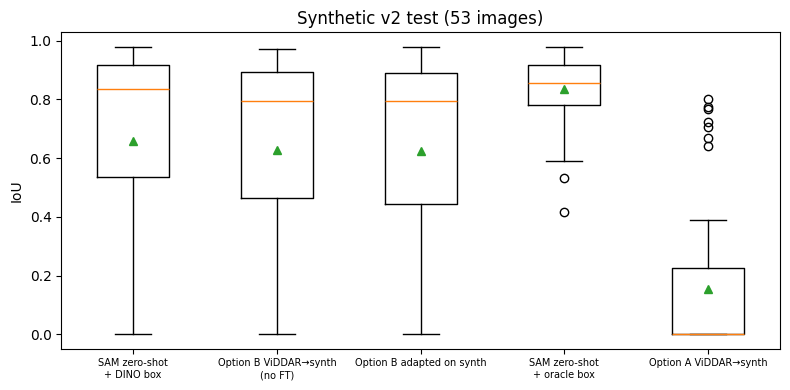

In [6]:
def bootstrap_ci(values, n_boot=10000, seed=0):
    values = np.asarray(values, dtype=float)
    rng = np.random.default_rng(seed)
    means = rng.choice(values, size=(n_boot, len(values)), replace=True).mean(axis=1)
    return np.percentile(means, [2.5, 97.5])


METHODS = {
    'ZS_DINO': ('SAM zero-shot + DINO box',
                lambda f: predict_mask_box(sam_baseline, cache_all[f], boxes_s[f])),
    'B_TRANSFER': ('Option B ViDDAR→synth (no FT)',
                   lambda f: predict_mask_box(sam_b_viddar if sam_b_viddar is not None else sam_baseline,
                                              cache_all[f], boxes_s[f])),
    'B_ADAPT': ('Option B adapted on synth',
                lambda f: predict_mask_box(sam_b_adapt, cache_all[f], boxes_s[f])),
    'ORACLE': ('SAM zero-shot + oracle box',
               lambda f: predict_mask_box(sam_baseline, cache_all[f], oracle_boxes[f])),
}
if HAS_OPTION_A and net_final is not None:
    METHODS['A'] = ('Option A ViDDAR→synth', lambda f: predict_mask_option_a(f))

# If no ViDDAR B, B_TRANSFER == ZS; still keep column for schema
if not HAS_OPTION_B:
    METHODS['B_TRANSFER'] = ('Option B ViDDAR→synth (fallback=ZS)', METHODS['ZS_DINO'][1])

rows = []
for fname in tqdm(test_common, desc='Test segmentation v2'):
    gt = cache_all[fname]['gt_full']
    row = {'file': fname,
           'class': labels_synth.loc[labels_synth['File Name'] == fname, 'Object Name'].iloc[0],
           'dino_query': labels_synth.loc[labels_synth['File Name'] == fname, 'dino_query'].iloc[0]}
    for key, (_, fn) in METHODS.items():
        pred = fn(fname)
        if pred.shape != gt.shape:
            pred = cv2.resize(pred, (gt.shape[1], gt.shape[0]), interpolation=cv2.INTER_NEAREST)
        row[f'{key}_iou'], row[f'{key}_dice'] = compute_iou_dice(pred, gt)
    rows.append(row)

per_image = pd.DataFrame(rows)
per_image.to_csv(f'{COMPARE_DIR}/test_per_image_segmentation.csv', index=False)

summary_rows = []
for key, (name, _) in METHODS.items():
    ious = per_image[f'{key}_iou'].values
    lo, hi = bootstrap_ci(ious)
    summary_rows.append({
        'método': name, 'n': len(ious), 'IoU': ious.mean(),
        'IoU IC95% inf': lo, 'IoU IC95% sup': hi,
        'Dice': per_image[f'{key}_dice'].mean(),
        'falhas (IoU<0.1)': int((ious < 0.1).sum()),
    })
summary = pd.DataFrame(summary_rows).set_index('método')
summary.to_csv(f'{COMPARE_DIR}/test_segmentation_summary.csv')
print(summary.round(4).to_string())

for a, b in [('B_ADAPT', 'ZS_DINO'), ('B_ADAPT', 'B_TRANSFER'), ('B_ADAPT', 'A')]:
    if a not in METHODS or b not in METHODS:
        continue
    diffs = per_image[f'{a}_iou'] - per_image[f'{b}_iou']
    lo, hi = bootstrap_ci(diffs)
    print(f"Paired {METHODS[a][0]} − {METHODS[b][0]}: {diffs.mean():+.4f} "
          f"(IC95% [{lo:+.4f}, {hi:+.4f}]"
          f"{' — significativa' if lo > 0 or hi < 0 else ' — inclui zero'})")

per_class = per_image.groupby('class')[[f'{k}_iou' for k in METHODS]].mean()
per_class.columns = [METHODS[k][0] for k in METHODS]
per_class.insert(0, 'n', per_image.groupby('class').size())
per_class.to_csv(f'{COMPARE_DIR}/test_per_class_iou.csv')
print('\nIoU by class:')
print(per_class.round(3).to_string())

fig, ax = plt.subplots(figsize=(max(8, 1.6 * len(METHODS)), 4))
ax.boxplot([per_image[f'{k}_iou'] for k in METHODS], showmeans=True)
ax.set_xticks(range(1, len(METHODS) + 1))
ax.set_xticklabels([METHODS[k][0].replace(' + ', '\n+ ').replace(' (', '\n(') for k in METHODS], fontsize=7)
ax.set_ylabel('IoU'); ax.set_title(f'Synthetic v2 test ({len(test_common)} images)')
plt.tight_layout()
plt.savefig(f'{COMPARE_DIR}/fig_test_iou_boxplot.png', dpi=200, bbox_inches='tight')
plt.show()

## [5] Obstruction (GT AR mask + estimated)

In [ ]:
DIFF_GRID = [10, 20, 30, 40, 50]
RATIO_GRID = [round(x, 2) for x in np.arange(0.05, 0.96, 0.05)]


def overlap_ratio(key_mask, content_mask):
    if content_mask.shape != key_mask.shape:
        content_mask = cv2.resize(content_mask, (key_mask.shape[1], key_mask.shape[0]),
                                  interpolation=cv2.INTER_NEAREST)
    return (key_mask.astype(bool) & content_mask.astype(bool)).sum() / (key_mask.sum() + 1e-6)


def obstruction_metrics(gts, preds):
    tn, fp, fn, tp = confusion_matrix(gts, preds, labels=[False, True]).ravel()
    return {'acc': float((preds == gts).mean()),
            'precision': float(precision_score(gts, preds, zero_division=0)),
            'recall': float(recall_score(gts, preds, zero_division=0)),
            'f1': float(f1_score(gts, preds, zero_division=0)),
            'fnr': float(fn / (fn + tp) if (fn + tp) > 0 else 0.0),
            'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp)}


def collect_obs(file_list, key_fns):
    ratios, gts = defaultdict(list), []
    for fname in tqdm(file_list, desc='Obstruction'):
        gts.append(labels_synth.loc[labels_synth['File Name'] == fname, 'obstruction'].iloc[0] == 'yes')
        raw = cv2.imread(os.path.join(RAW_DIR_S, fname))
        ar = cv2.imread(os.path.join(AR_DIR_S, f'AR_{fname}'))
        if ar.shape != raw.shape:
            ar = cv2.resize(ar, (raw.shape[1], raw.shape[0]))
        dg = cv2.cvtColor(cv2.absdiff(raw, ar), cv2.COLOR_BGR2GRAY)
        gt_c = (cv2.imread(os.path.join(AR_MASK_DIR_S, f'mask_{fname}'), cv2.IMREAD_GRAYSCALE) > 127).astype(np.uint8)
        for kn, kfn in key_fns.items():
            km = kfn(fname)
            for d in DIFF_GRID:
                ratios[(kn, f'diff{d}')].append(overlap_ratio(km, (dg > d).astype(np.uint8)))
            ratios[(kn, 'gt')].append(overlap_ratio(km, gt_c))
    return {k: np.array(v) for k, v in ratios.items()}, np.array(gts)


val_common = [f for f in splits_synth['val']
              if boxes_s.get(f) is not None and oracle_boxes.get(f) is not None]

key_fns = {
    'GT': lambda f: cache_all[f]['gt_full'],
    'ZS': lambda f: predict_mask_box(sam_baseline, cache_all[f], boxes_s[f]),
    'B_ADAPT': lambda f: predict_mask_box(sam_b_adapt, cache_all[f], boxes_s[f]),
}
if HAS_OPTION_A and net_final is not None:
    key_fns['A'] = predict_mask_option_a

val_ratios, val_gts = collect_obs(val_common, key_fns)
test_ratios, test_gts = collect_obs(test_common, key_fns)


def tune(key_name, content):
    diffs = DIFF_GRID if content == 'estimated' else [None]
    best = None
    for d in diffs:
        r = val_ratios[(key_name, f'diff{d}' if d is not None else 'gt')]
        for t in RATIO_GRID:
            m = obstruction_metrics(val_gts, r >= t)
            score = (m['f1'], m['acc'])
            if best is None or score > best[0]:
                best = (score, d, t)
    return best[1], best[2]


results = []
for kn in key_fns:
    configs = [('fixed (30, 0.25)', 'estimated', 30, 0.25)]
    for content in ('estimated', 'gt'):
        d, t = tune(kn, content)
        configs.append(('tuned on val', content, d, t))
    for how, content, d, t in configs:
        r = test_ratios[(kn, f'diff{d}' if content == 'estimated' else 'gt')]
        m = obstruction_metrics(test_gts, r >= t)
        results.append({'key mask': kn, 'AR content': content, 'thresholds': how,
                        'diff_thr': d, 'ratio_thr': t, **m})

obs = pd.DataFrame(results)
obs.to_csv(f'{COMPARE_DIR}/obstruction_metrics.csv', index=False)
print(obs.round(4).to_string(index=False))

## [6] Compare v1 vs v2 vs ViDDAR

=== IoU comparison ===
                            ViDDAR  Synth v1  Synth v2  n_v2  Δ v2−v1
método                                                               
SAM zero-shot + DINO box    0.8686    0.5657    0.6566    53   0.0909
Option B (transfer)            NaN    0.5481    0.6257    53   0.0776
Option B (adapted)             NaN    0.5481    0.6240    53   0.0759
SAM zero-shot + oracle box  0.8945    0.8582    0.8345    53  -0.0237
Option A                    0.6863    0.0813    0.1537    53   0.0724

Expected gains vs v1:
  - Higher DINO recall / more test images in the common set
  - Higher ZS DINO IoU from specific queries + synonyms
  - Adapted B should beat transfer B and ideally approach oracle more closely
  - More balanced per-class scores (less vehicle dominance)


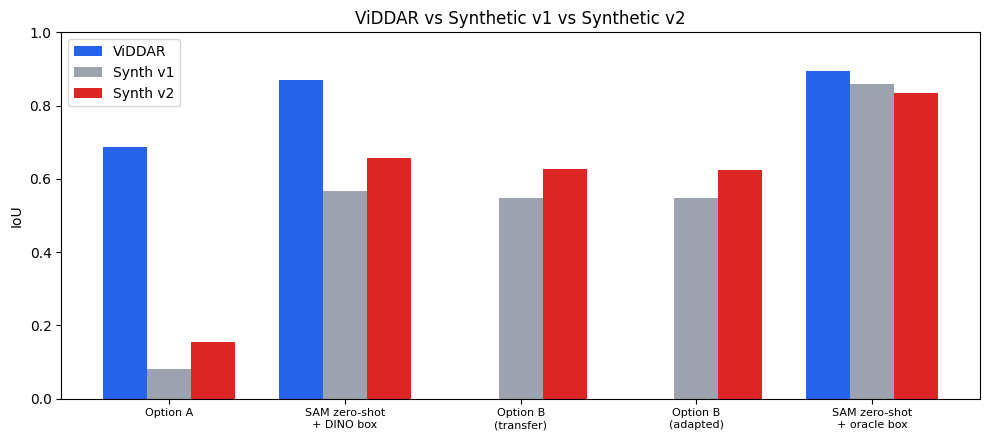


All outputs: /content/drive/MyDrive/viddar_samed/cross_dataset_v2


In [8]:
# Hardcoded ViDDAR Entrega-2 + v1 synthetic numbers (from Results notebook)
VIDDAR = {
    'Option A': 0.6863,
    'SAM zero-shot + DINO box': 0.8686,
    'Option B': 0.8855,
    'SAM zero-shot + oracle box': 0.8945,
}
V1_SYNTH = {
    'Option A': 0.0813,
    'SAM zero-shot + DINO box': 0.5657,
    'Option B (transfer)': 0.5481,
    'SAM zero-shot + oracle box': 0.8582,
}

v2_map = {
    'Option A ViDDAR→synth': 'Option A',
    'SAM zero-shot + DINO box': 'SAM zero-shot + DINO box',
    'Option B ViDDAR→synth (no FT)': 'Option B (transfer)',
    'Option B adapted on synth': 'Option B (adapted)',
    'SAM zero-shot + oracle box': 'SAM zero-shot + oracle box',
}

rows = []
for metodo, row in summary.iterrows():
    canon = v2_map.get(metodo, metodo)
    v1 = V1_SYNTH.get(canon, np.nan)
    if canon == 'Option B (adapted)':
        v1 = V1_SYNTH.get('Option B (transfer)', np.nan)
    rows.append({'método': canon, 'ViDDAR': VIDDAR.get(canon, np.nan),
                 'Synth v1': v1, 'Synth v2': row['IoU'], 'n_v2': int(row['n'])})

cmp = pd.DataFrame(rows).drop_duplicates('método').set_index('método')

cmp['Δ v2−v1'] = cmp['Synth v2'] - cmp['Synth v1']
cmp.to_csv(f'{COMPARE_DIR}/comparison_v1_v2_viddar.csv')
print('=== IoU comparison ===')
print(cmp.round(4).to_string())

# highlight gains
print('\nExpected gains vs v1:')
print('  - Higher DINO recall / more test images in the common set')
print('  - Higher ZS DINO IoU from specific queries + synonyms')
print('  - Adapted B should beat transfer B and ideally approach oracle more closely')
print('  - More balanced per-class scores (less vehicle dominance)')

fig, ax = plt.subplots(figsize=(10, 4.5))
methods = [m for m in ['Option A', 'SAM zero-shot + DINO box', 'Option B (transfer)',
                       'Option B (adapted)', 'SAM zero-shot + oracle box'] if m in cmp.index]
x = np.arange(len(methods)); w = 0.25
ax.bar(x - w, [cmp.loc[m, 'ViDDAR'] if pd.notna(cmp.loc[m, 'ViDDAR']) else 0 for m in methods],
       w, label='ViDDAR', color='#2563eb')
ax.bar(x, [cmp.loc[m, 'Synth v1'] if pd.notna(cmp.loc[m, 'Synth v1']) else 0 for m in methods],
       w, label='Synth v1', color='#9ca3af')
ax.bar(x + w, [cmp.loc[m, 'Synth v2'] if pd.notna(cmp.loc[m, 'Synth v2']) else 0 for m in methods],
       w, label='Synth v2', color='#dc2626')
ax.set_xticks(x)
ax.set_xticklabels([m.replace(' + ', '\n+ ').replace(' (', '\n(') for m in methods], fontsize=8)
ax.set_ylim(0, 1); ax.set_ylabel('IoU'); ax.legend()
ax.set_title('ViDDAR vs Synthetic v1 vs Synthetic v2')
plt.tight_layout()
plt.savefig(f'{COMPARE_DIR}/fig_v1_v2_viddar_iou.png', dpi=200, bbox_inches='tight')
plt.show()
print(f'\nAll outputs: {COMPARE_DIR}')

## [7] Qualitative examples

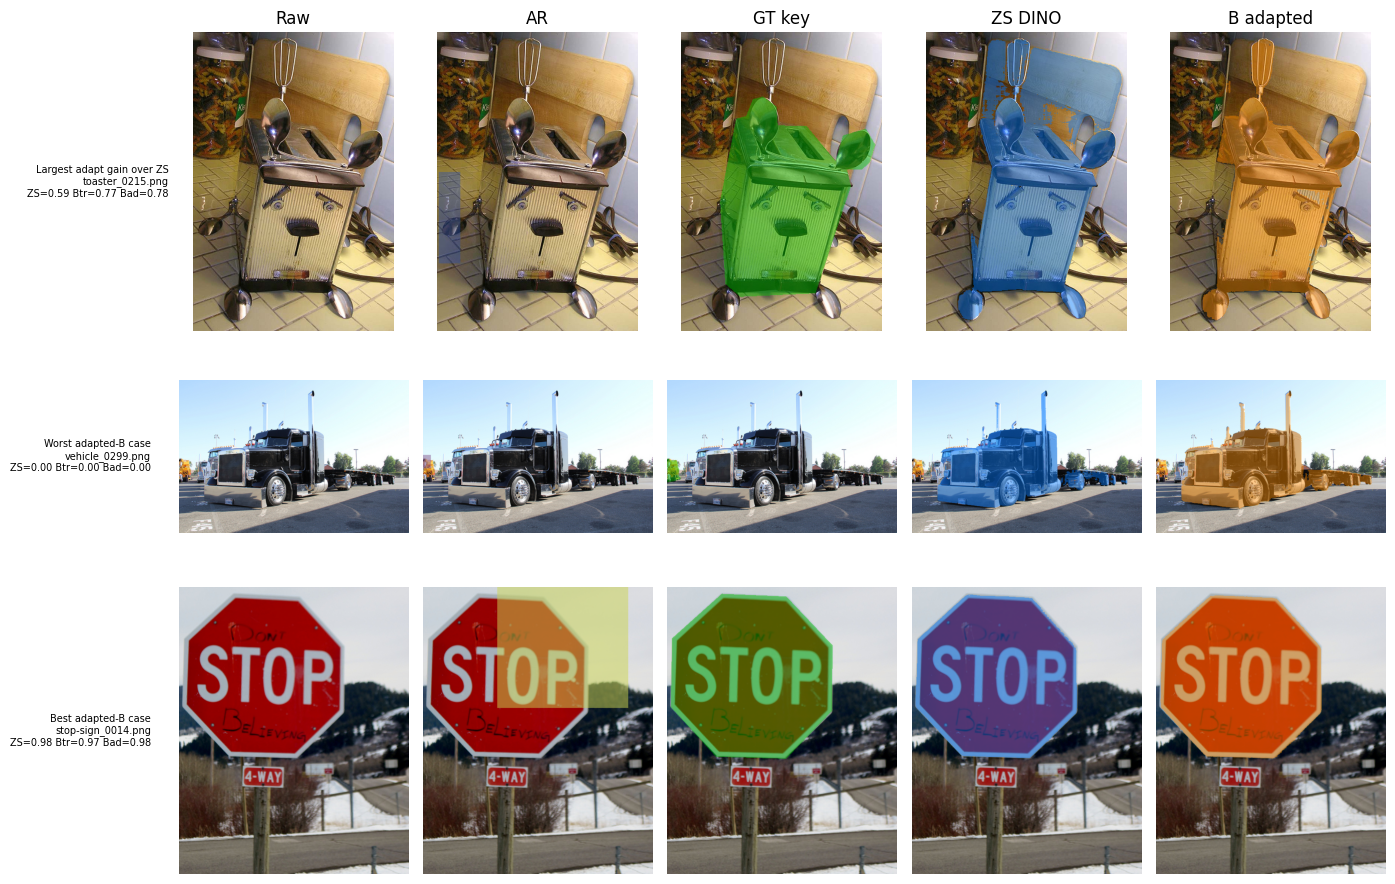

In [9]:
def overlay_mask(image_rgb, mask, color=(255, 140, 0), alpha=0.45):
    img = np.array(image_rgb).copy(); over = img.copy()
    over[mask.astype(bool)] = color
    return cv2.addWeighted(over, alpha, img, 1 - alpha, 0)


df = per_image.copy()
df['gain'] = df['B_ADAPT_iou'] - df['ZS_DINO_iou']
gain_f = df.sort_values('gain', ascending=False).iloc[0]['file']
fail_f = df.sort_values('B_ADAPT_iou', ascending=True).iloc[0]['file']
best_f = df.sort_values('B_ADAPT_iou', ascending=False).iloc[0]['file']
selected = [gain_f, fail_f, best_f]
labels_rows = ['Largest adapt gain over ZS', 'Worst adapted-B case', 'Best adapted-B case']

fig, axes = plt.subplots(3, 5, figsize=(14, 9))
titles = ['Raw', 'AR', 'GT key', 'ZS DINO', 'B adapted']
for i, fname in enumerate(selected):
    raw = Image.open(os.path.join(RAW_DIR_S, fname)).convert('RGB')
    ar = Image.open(os.path.join(AR_DIR_S, f'AR_{fname}')).convert('RGB')
    gt = cache_all[fname]['gt_full']
    panels = [
        np.array(raw), np.array(ar),
        overlay_mask(raw, gt, (0, 200, 0)),
        overlay_mask(raw, predict_mask_box(sam_baseline, cache_all[fname], boxes_s[fname]), (0, 120, 255)),
        overlay_mask(raw, predict_mask_box(sam_b_adapt, cache_all[fname], boxes_s[fname]), (255, 140, 0)),
    ]
    for j, p in enumerate(panels):
        axes[i, j].imshow(p); axes[i, j].axis('off')
        if i == 0:
            axes[i, j].set_title(titles[j])
    info = df[df.file == fname].iloc[0]
    axes[i, 0].text(-0.12, 0.5,
                    f"{labels_rows[i]}\n{fname}\nZS={info['ZS_DINO_iou']:.2f} "
                    f"Btr={info['B_TRANSFER_iou']:.2f} Bad={info['B_ADAPT_iou']:.2f}",
                    transform=axes[i, 0].transAxes, fontsize=7, va='center', ha='right')
plt.tight_layout()
plt.savefig(f'{COMPARE_DIR}/fig_qualitative_v2.png', dpi=200, bbox_inches='tight')
plt.show()